# 01 — Explore the data

Check missing values, duplicates, class balance and relationships. These are synthetic student labels.

Open from the notebooks folder. Saved outputs are from the earlier execution; the simplified source has not been rerun in full.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from sklearn.model_selection import train_test_split

numeric_columns = [
    'Age', 'Year_of_Study', 'Sleep_Hours', 'Study_Hours_Per_Week', 'GPA',
    'Social_Media_Hours', 'Screen_Time_Hours', 'Financial_Stress',
    'Family_Support', 'Attendance_Rate',
]
categorical_columns = [
    'Gender', 'Physical_Activity', 'Part_Time_Job', 'Diet_Quality',
    'Previous_Mental_Health_History',
]

df = pd.read_csv('../data/raw/student_mental_health.csv')
display(df.head())
print(df.shape)

,Student_ID,Age,Gender,Year_of_Study,Sleep_Hours,Study_Hours_Per_Week,GPA,Social_Media_Hours,Screen_Time_Hours,Physical_Activity,Financial_Stress,Family_Support,Attendance_Rate,Part_Time_Job,Diet_Quality,Previous_Mental_Health_History,Mental_Health_Risk
0,STU0001,22,Male,3,6.6,17.6,2.91,6.9,7.5,Moderate,8.5,4.0,78.0,No,Poor,No,High
1,STU0002,21,Male,4,5.6,22.4,2.92,7.6,11.5,Low,4.5,5.3,85.4,Yes,Average,No,Medium
2,STU0003,22,Male,5,7.1,28.1,2.68,6.5,8.9,Low,4.8,6.1,79.5,No,Average,No,Medium
3,STU0004,24,Male,1,4.5,14.8,2.23,5.5,7.6,High,3.7,8.0,73.9,No,Average,Yes,High
4,STU0005,20,Female,1,6.7,17.2,2.69,4.3,7.0,Moderate,8.0,7.4,99.8,Yes,NaN,No,Medium


(2000, 17)


## Missing values and duplicates

Check the raw data before choosing how to handle missing answers.

In [2]:
display(df.dtypes)
display(df.isna().sum())
print('Duplicate rows:', df.duplicated().sum())
print('Duplicate IDs:', df['Student_ID'].duplicated().sum())
display(df.describe())

Student_ID                            str
Age                                 int64
Gender                                str
Year_of_Study                       int64
Sleep_Hours                       float64
Study_Hours_Per_Week              float64
GPA                               float64
Social_Media_Hours                float64
Screen_Time_Hours                 float64
Physical_Activity                     str
Financial_Stress                  float64
Family_Support                    float64
Attendance_Rate                   float64
Part_Time_Job                         str
Diet_Quality                          str
Previous_Mental_Health_History        str
Mental_Health_Risk                    str
dtype: object

Student_ID                         0
Age                                0
Gender                             0
Year_of_Study                      0
Sleep_Hours                       62
Study_Hours_Per_Week               0
GPA                               38
Social_Media_Hours                58
Screen_Time_Hours                  0
Physical_Activity                  0
Financial_Stress                  91
Family_Support                    54
Attendance_Rate                   47
Part_Time_Job                      0
Diet_Quality                      69
Previous_Mental_Health_History     0
Mental_Health_Risk                 0
dtype: int64

Duplicate rows: 0
Duplicate IDs: 0


,Age,Year_of_Study,Sleep_Hours,Study_Hours_Per_Week,GPA,Social_Media_Hours,Screen_Time_Hours,Financial_Stress,Family_Support,Attendance_Rate
count,2000.000000,2000.000000,1938.000000,2000.000000,1962.000000,1942.000000,2000.000000,1909.000000,1946.000000,1953.000000
mean,21.131500,2.630000,6.758875,19.997900,2.562503,6.013955,8.548500,5.956260,6.518345,85.080236
std,2.139275,1.316802,1.127072,5.719274,0.343993,1.153422,1.657571,1.893941,1.844639,7.224118
min,17.000000,1.000000,3.300000,2.400000,1.500000,2.100000,3.300000,1.400000,1.700000,54.400000
25%,20.000000,1.000000,6.000000,16.000000,2.320000,5.225000,7.400000,4.500000,5.100000,80.300000
50%,21.000000,2.000000,6.700000,19.800000,2.560000,6.000000,8.500000,6.100000,6.700000,85.100000
75%,23.000000,4.000000,7.600000,24.000000,2.790000,6.700000,9.700000,7.400000,8.000000,90.000000
max,29.000000,5.000000,10.000000,38.300000,3.660000,10.000000,14.000000,10.000000,9.900000,100.000000


## Keep the test set separate

Use 80% training and 20% test data. Explore training relationships only.

Mental_Health_Risk
Low       528
Medium    528
High      544
Name: count, dtype: int64

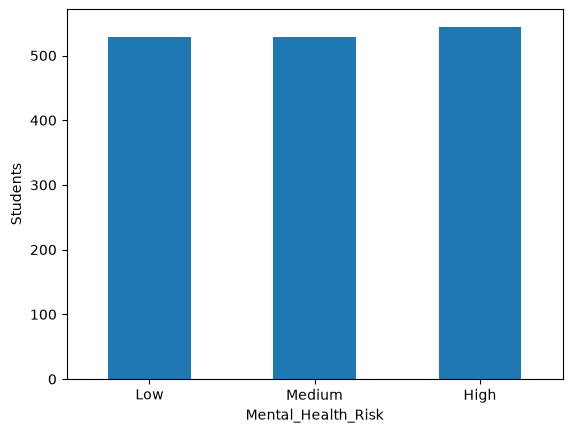

In [3]:
X = df[numeric_columns + categorical_columns]
y = df['Mental_Health_Risk']
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)
counts = y_train.value_counts().reindex(['Low', 'Medium', 'High'])
display(counts)
counts.plot.bar(rot=0)
plt.ylabel('Students')
plt.savefig('../reports/figures/class_distribution.png')
plt.show()

## Numeric values

Classes are nearly balanced, so resampling is unnecessary. Use IQR to identify unusual values, but keep plausible extremes.

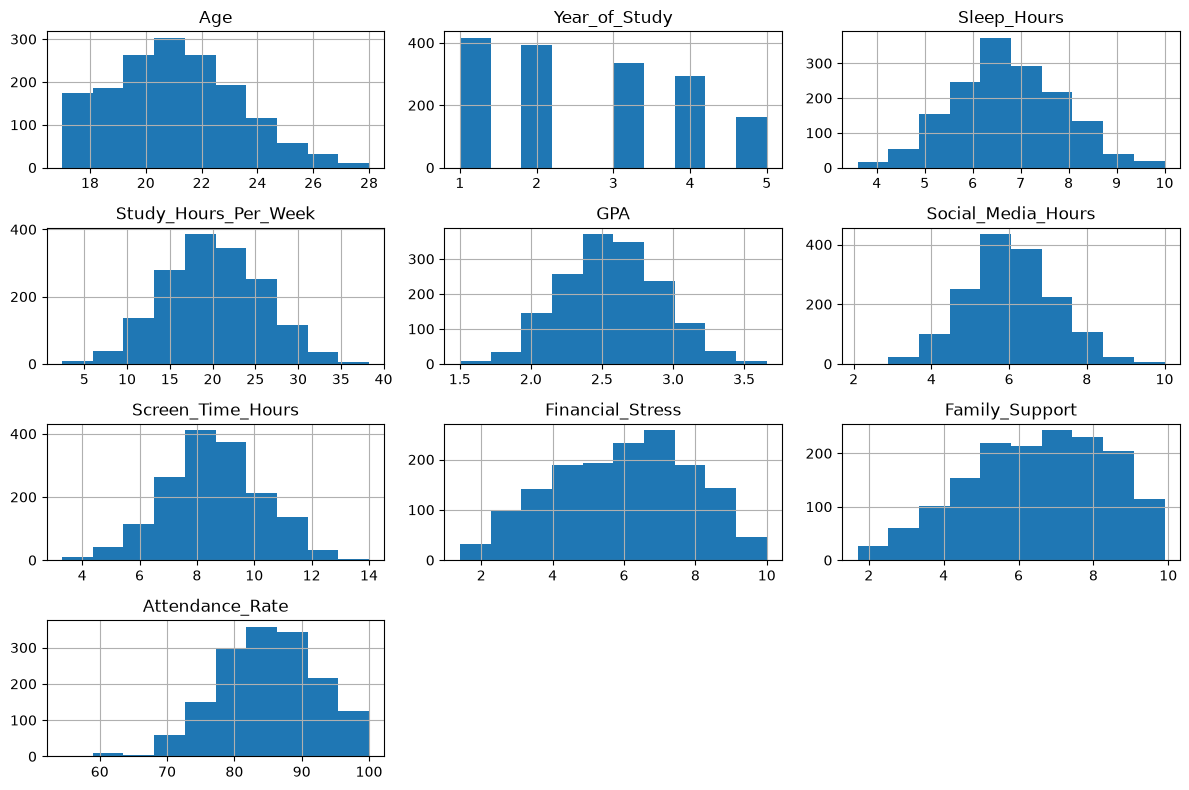

Age                      2
Year_of_Study            0
Sleep_Hours              9
Study_Hours_Per_Week     7
GPA                      5
Social_Media_Hours      10
Screen_Time_Hours        7
Financial_Stress         0
Family_Support           0
Attendance_Rate         10
dtype: int64

In [5]:
X_train[numeric_columns].hist(figsize=(12, 8))
plt.tight_layout()
plt.savefig('../reports/figures/numeric_distributions.png')
plt.show()
q1 = X_train[numeric_columns].quantile(0.25)
q3 = X_train[numeric_columns].quantile(0.75)
iqr = q3 - q1
outliers = (X_train[numeric_columns] < q1 - 1.5 * iqr) | (X_train[numeric_columns] > q3 + 1.5 * iqr)
display(outliers.sum())

## Correlations

Relationships below use training data only and do not establish cause and effect.

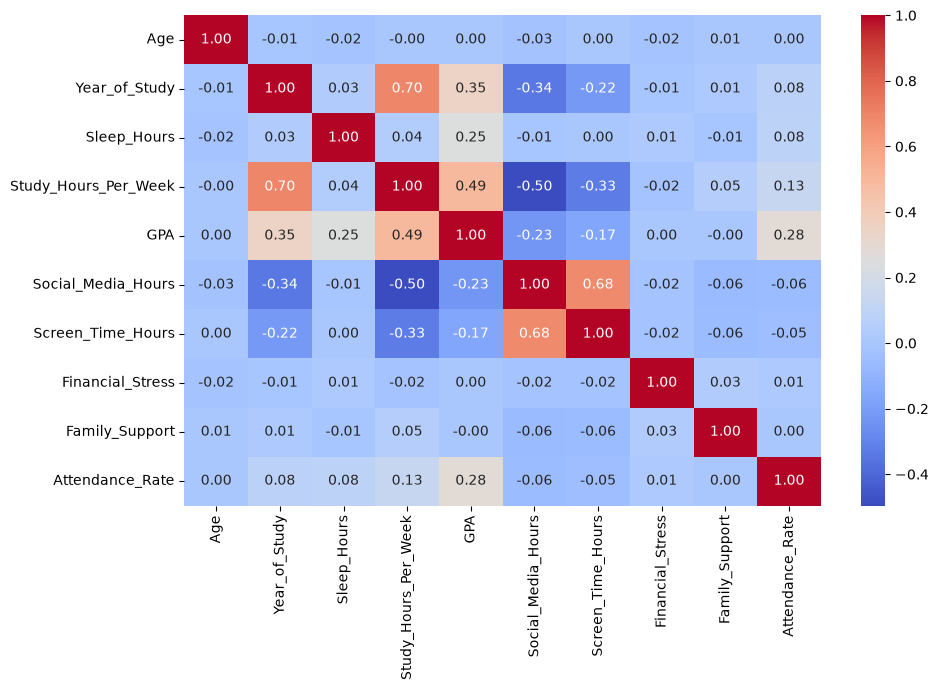

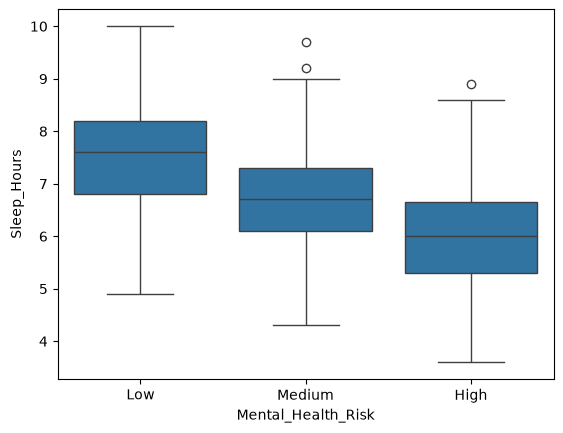

In [6]:
plt.figure(figsize=(10, 7))
sns.heatmap(X_train[numeric_columns].corr(), annot=True, fmt='.2f', cmap='coolwarm')
plt.tight_layout()
plt.savefig('../reports/figures/correlations.png')
plt.show()
sns.boxplot(x=y_train, y=X_train['Sleep_Hours'], order=['Low', 'Medium', 'High'])
plt.savefig('../reports/figures/features_by_risk.png')
plt.show()

## Categorical values

Compare the class proportions within each category.

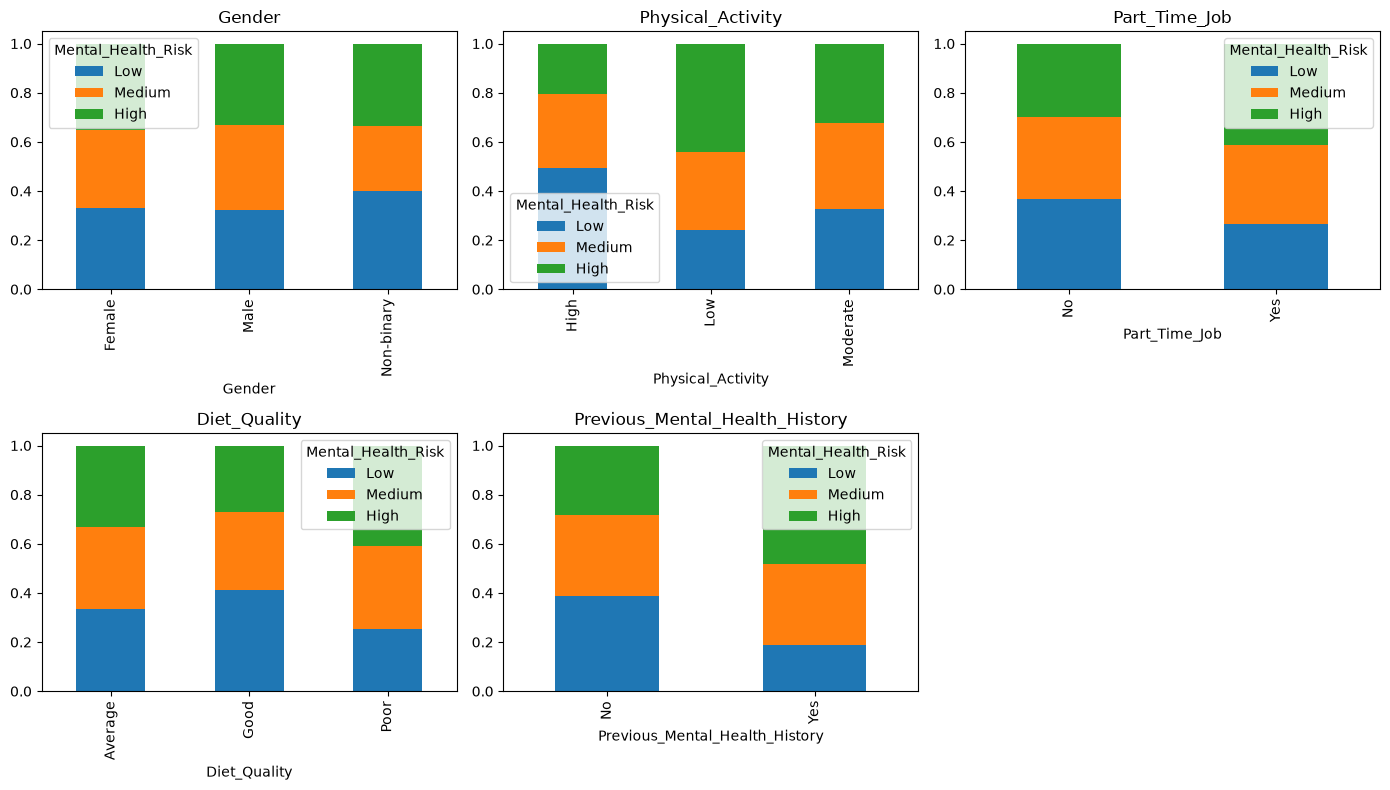

In [7]:
fig, axes = plt.subplots(2, 3, figsize=(14, 8))
for ax, column in zip(axes.flat, categorical_columns):
    table = pd.crosstab(X_train[column], y_train, normalize='index')
    table.reindex(columns=['Low', 'Medium', 'High']).plot.bar(stacked=True, ax=ax)
    ax.set_title(column)
axes.flat[-1].axis('off')
plt.tight_layout()
plt.savefig('../reports/figures/categorical_relationships.png')
plt.show()

## Decisions

Exclude Student_ID. Fill missing numbers with training medians and categories with training modes. Scale numbers and encode categories inside model pipelines. Keep valid extreme values. Synthetic label associations are not clinical evidence.